# Imports

In [1]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions.utils import probs_to_logits
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage

from nielsen_shared import BASE_DIR, get_brand_form
from utils import get_device, canonicalize
from training import load_checkpoint, _compute_sqrt_L
from analysis import load_time_covariance
from config_plt import config_plt, save_my_fig

In [3]:
pd.set_option("display.max_rows", 1000)
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_colwidth", 500)
pd.set_option('future.no_silent_downcasting', True)

device = get_device()
config_plt()

# Load Data

NOTE: price and promotion are missing when the alternative is unavailable

In [4]:
# Purchases per household
df = pd.read_csv(os.path.join(BASE_DIR, "full_panel.csv")).sort_values(by=["household_code", "purchase_date"])
num_total_purchases = df.shape[0]
household_value_counts = df["household_code"].value_counts()
household_value_counts_10_plus = household_value_counts >= 10
household_value_counts_30_below = household_value_counts <= 30
household_value_counts_in_range = household_value_counts_10_plus & household_value_counts_30_below
households_in_range = household_value_counts.index[household_value_counts_in_range]
print(f"Total number of households: {household_value_counts_10_plus.shape[0]}")
print(f"Proportion of households with 10+ purchases: {household_value_counts_10_plus.mean()}")
print(f"Proportion of households with <=30 purchases: {household_value_counts_30_below.mean()}")
print(f"Households with 10+ purchases: {household_value_counts_10_plus.sum()}")
print(f"Households with 10-30 purchases: {household_value_counts_in_range.sum()}")

df = df[df["household_code"].isin(households_in_range)]
household_codes = np.sort(households_in_range)
household_code_lookup = dict(zip(household_codes.tolist(), range(household_codes.size)))
df["household_id"] = df["household_code"].replace(household_code_lookup)
num_purchases_in_range = df.shape[0]

print(f"Number of purchases before filtering: {num_total_purchases}")
print(f"Number of purchases after filtering: {num_purchases_in_range}")

Total number of households: 33284
Proportion of households with 10+ purchases: 0.16827905299843768
Proportion of households with <=30 purchases: 0.978938829467612
Households with 10+ purchases: 5601
Households with 10-30 purchases: 4900
Number of purchases before filtering: 192001
Number of purchases after filtering: 78047


# Generate Summaries

In [5]:
# brand_form ID
df_brand_form = get_brand_form(filter_columns=False).sort_values(by="brand_form").reset_index(drop=True)
brand_forms = df_brand_form["brand_form"].tolist()
brands = [b for b in df_brand_form["brand"].unique() if b != "OTHER"]
forms = df_brand_form[~df_brand_form["form"].isna()]["form"].unique().tolist()
brand_form_lookup = dict(zip(brand_forms, range(len(brand_forms))))
df["brand_form_id"] = df["brand_form"].replace(brand_form_lookup).astype(int)
brand_lookup = dict(df_brand_form[["brand_form", "brand"]].values)
form_lookup = dict(df_brand_form[["brand_form", "form"]].values)
form_lookup["OTHER"] = "OTHER"
df["brand: OTHER"] = 0.
df["form: OTHER"] = 0.

In [6]:
# brand_form columns and choice sets
loyalty_columns = [f"loyalty: {bf}" for bf in brand_forms]
brand_loyalty_columns = [f"brand: {brand_lookup[bf]}" for bf in brand_forms]
form_loyalty_columns = [f"form: {form_lookup[bf]}" for bf in brand_forms]
coupon_columns = [f"coupon: {bf}" for bf in brand_forms]
price_columns = [f"price: {bf}" for bf in brand_forms]
promotion_columns = [f"promotion: {bf}" for bf in brand_forms]
bf_is_available = ~df[price_columns].isna()
num_bfs_available = bf_is_available.sum(axis=1)
df["choice_set_size"] = num_bfs_available

In [7]:
# Average prices
bf_vc = df["brand_form"].value_counts().sort_index().reset_index(drop=True)
bf_props = bf_vc / bf_vc.sum()
df_price = df[price_columns].mean().sort_index().reset_index(drop=True)
df_coupon = df[coupon_columns].mean().sort_index().reset_index(drop=True)
df_promotion = df[promotion_columns].mean().sort_index().reset_index(drop=True)
df_missing = df[price_columns].isna().mean().sort_index().reset_index(drop=True)

df_summary = pd.concat([bf_props, df_price, df_coupon, df_promotion, df_missing], axis=1)
df_summary.columns = ["Share", "Price/Load", "Coupon", "Promo", "Missing"]
df_summary.insert(0, "Brand", df_brand_form["brand"].str.title())
df_summary.insert(1, "Form", df_brand_form["form"].str.title().fillna("-"))
df_summary.insert(2, "Revenue Share", df_brand_form["total_price_paid"])
df_summary = df_summary.sort_values(by="Share", ascending=False).reset_index(drop=True)
df_summary_subset = df_summary.drop("Revenue Share", axis=1)
df_summary_subset["Share"] = df_summary_subset["Share"].apply(lambda x: f"{100*x:.2f}%")
df_summary_subset["Price/Load"] = df_summary_subset["Price/Load"].apply(lambda x: f"${x:.4f}")
df_summary_subset["Missing"] = df_summary_subset["Missing"].apply(lambda x: f"{100*x:.2f}%")
df_summary_subset["Coupon"] = df_summary_subset["Coupon"].apply(lambda x: f"{100*x:.2f}%")
df_summary_subset["Promo"] = df_summary_subset["Promo"].apply(lambda x: f"{100*x:.2f}%")
df_summary_subset

,Brand,Form,Share,Price/Load,Coupon,Promo,Missing
0,Tide,Liquid,27.69%,$0.1334,5.52%,6.25%,0.00%
1,Arm & Hammer,Liquid,14.83%,$0.0821,2.97%,3.37%,0.51%
2,Tide,Unit Dose,12.16%,$0.3428,4.86%,5.13%,0.06%
3,Other,-,11.63%,$0.1565,2.69%,1.69%,0.14%
4,All,Liquid,10.46%,$0.1168,5.94%,2.96%,0.47%
5,Purex,Liquid,5.82%,$0.0687,4.46%,2.34%,11.08%
6,Persil,Liquid,5.20%,$0.1393,8.10%,2.80%,1.45%
7,Gain,Liquid,5.09%,$0.1140,4.34%,4.33%,0.26%
8,All,Unit Dose,2.56%,$0.2695,4.19%,1.65%,4.34%
9,Gain,Unit Dose,2.44%,$0.3071,4.13%,3.14%,1.19%


In [8]:
table = (df_summary_subset.to_latex(index=False, escape=True)
    .replace(r"Arm \& Hammer", r"A\&H")
    .replace("lllllll", "lcrrrrr")
)
print(table)

\begin{tabular}{lcrrrrr}
\toprule
Brand & Form & Share & Price/Load & Coupon & Promo & Missing \\
\midrule
Tide & Liquid & 27.69\% & \$0.1334 & 5.52\% & 6.25\% & 0.00\% \\
A\&H & Liquid & 14.83\% & \$0.0821 & 2.97\% & 3.37\% & 0.51\% \\
Tide & Unit Dose & 12.16\% & \$0.3428 & 4.86\% & 5.13\% & 0.06\% \\
Other & - & 11.63\% & \$0.1565 & 2.69\% & 1.69\% & 0.14\% \\
All & Liquid & 10.46\% & \$0.1168 & 5.94\% & 2.96\% & 0.47\% \\
Purex & Liquid & 5.82\% & \$0.0687 & 4.46\% & 2.34\% & 11.08\% \\
Persil & Liquid & 5.20\% & \$0.1393 & 8.10\% & 2.80\% & 1.45\% \\
Gain & Liquid & 5.09\% & \$0.1140 & 4.34\% & 4.33\% & 0.26\% \\
All & Unit Dose & 2.56\% & \$0.2695 & 4.19\% & 1.65\% & 4.34\% \\
Gain & Unit Dose & 2.44\% & \$0.3071 & 4.13\% & 3.14\% & 1.19\% \\
Masked & Liquid & 2.14\% & \$0.0979 & 4.73\% & 1.31\% & 12.31\% \\
\bottomrule
\end{tabular}



In [9]:
df["choice_set_size"].value_counts()

choice_set_size
11    58700
10    15258
9      3163
8       660
7       162
6        43
5        38
4        12
3         9
2         2
Name: count, dtype: int64

In [10]:
RESULTS = "./analysis-results"
EMULATOR_DIR = os.path.join(RESULTS, "emulator_models")
DENSE_DIR = os.path.join(RESULTS, "dense_time_models")
K_TIME = 10                  # dense time covariance: n_factors_time = n_brand_forms - 1
DENSE_START_FACTORS = [-1, 7]

def load_summary(path):
    with open(path) as f:
        return json.load(f)


def total_fit_time(paths):
    """Summed optimizer time (s) of every fit among `paths` that was run."""
    found = [p for p in paths if os.path.exists(p)]
    if not found:
        raise FileNotFoundError(f"None of {paths}")
    return sum(load_summary(p)["elapsed_time"] for p in found)


def factor_fit_time(name, tf):
    """All fits of emulator `name` at tf: the initial fit plus its refit attempt, if any."""
    if name == "probit":     # a single fit, no competitive refinement
        return load_summary(os.path.join(EMULATOR_DIR, f"{name}_dense_tf{tf}.json"))["elapsed_time"]
    return total_fit_time([os.path.join(EMULATOR_DIR, "intermediate", f"{name}_dense_tf{tf}_{stage}.json")
                           for stage in ("initial", "refit")])


def dense_fit_time(name):
    """All fits of dense emulator `name`: one per starting point plus its refit attempt, if any."""
    stages = [f"from_tf{tf}" for tf in DENSE_START_FACTORS] + ["refit"]
    return total_fit_time([os.path.join(DENSE_DIR, "intermediate", f"{name}_dense_tf{K_TIME}_{stage}.json")
                           for stage in stages])


rows = []
for family, name in [("MNP", "probit"), ("correlated-Gumbel", "gumbel-large")]:
    for tf in range(-1, 8):
        s = load_summary(os.path.join(EMULATOR_DIR, f"{name}_dense_tf{tf}.json"))
        rows.append({"emulator": family, "n_factors_time": tf, "loglike": s["log_likelihood"],
                     "n_params": s["n_params"], "bic": s["bic"], "time_s": factor_fit_time(name, tf)})
    s = load_summary(os.path.join(DENSE_DIR, f"{name}_dense_dense_tf{K_TIME}.json"))   # best fit
    rows.append({"emulator": family, "n_factors_time": K_TIME, "loglike": s["log_likelihood"],
                 "n_params": s["n_params"], "bic": s["bic"], "time_s": dense_fit_time(f"{name}_dense")})
df_results = pd.DataFrame(rows)

# Rows whose time differs from analysis-results.csv (a refit attempt step 3 did not keep)
df_csv = pd.read_csv(os.path.join(EMULATOR_DIR, "analysis-results.csv"))
check = df_results.assign(emulator=df_results["emulator"].map({"MNP": "probit", "correlated-Gumbel": "gumbel-large"}))
check = check.merge(df_csv[["emulator", "n_factors_time", "time_s"]], on=["emulator", "n_factors_time"],
                    suffixes=("", "_csv"))
print(check.loc[(check["time_s"] - check["time_s_csv"]).abs() > 1e-6,
                ["emulator", "n_factors_time", "time_s", "time_s_csv"]].to_string(index=False))

df_results["n_factors_time"] = df_results["n_factors_time"].replace({
    -1: "IID",
    0: "Independent",
    1: "1-Factor",
    2: "2-Factor",
    3: "3-Factor",
    4: "4-Factor",
    5: "5-Factor",
    6: "6-Factor",
    7: "7-Factor",
    K_TIME: "Dense",
})
df_results["loglike"] = df_results["loglike"].apply(lambda x: f"{x:,.1f}")
df_results["bic"] = df_results["bic"].apply(lambda x: f"{x:,.1f}")
df_results["time_h"] = df_results["time_s"].apply(lambda x: f"{x/3600:,.1f}")
df_results = df_results.rename({
    "emulator": "Family",
    "n_factors_time": "Cov. Type",
    "loglike": "Log Like.",
    "n_params": "# Params.",
    "bic": "BIC",
    "time_h": "Time (h)",
}, axis=1)
df_results = df_results[["Family", "Cov. Type", "BIC", "# Params.", "Time (h)"]]
df_results = df_results.set_index(["Family", "Cov. Type"])
latex_results = (df_results
    .reset_index()
    .to_latex(escape=True, index=False)
    .replace("MNP", r"\multirow{10}{*}{MNP}", 1)
    .replace("MNP ", " ")
    .replace("BIC", r"\multicolumn{1}{c}{BIC}")
    .replace("correlated-Gumbel", r"\multirow{10}{*}{correlated-Gumbel}", 1)
    .replace(" \\\\\n\\mu", "\\vspace{6pt}\\\\\n\\mu")
    .replace("correlated-Gumbel ", " ")
    .replace("lllrl", "llrcc")
    .replace("191,539.6", r"\textbf{191,539.6}")
    .replace("191,092.6", r"\textbf{191,092.6}")
)
print(latex_results)

    emulator  n_factors_time      time_s  time_s_csv
gumbel-large               2 8632.307006 4807.370812
gumbel-large               6 9578.598635 6047.086505
gumbel-large               7 5308.634000 1929.883280
\begin{tabular}{llrcc}
\toprule
Family & Cov. Type & \multicolumn{1}{c}{BIC} & \# Params. & Time (h) \\
\midrule
\multirow{10}{*}{MNP} & IID & 192,545.0 & 107 & 0.2 \\
 & Independent & 191,846.0 & 116 & 2.3 \\
 & 1-Factor & 191,635.2 & 125 & 0.9 \\
 & 2-Factor & 191,639.2 & 133 & 1.5 \\
 & 3-Factor & 191,539.6 & 140 & 1.1 \\
 & 4-Factor & 191,568.3 & 146 & 0.8 \\
 & 5-Factor & 191,608.8 & 151 & 0.6 \\
 & 6-Factor & 191,619.5 & 155 & 1.7 \\
 & 7-Factor & 191,645.0 & 158 & 0.3 \\
 & Dense & 191,564.7 & 161 & 7.6\vspace{6pt}\\
\multirow{10}{*}{correlated-Gumbel} & IID & 192,106.8 & 107 & 0.9 \\
 & Independent & 191,379.0 & 116 & 2.9 \\
 & 1-Factor & 191,120.1 & 125 & 3.1 \\
 & 2-Factor & 191,155.4 & 133 & 2.4 \\
 & 3-Factor & 191,092.6 & 140 & 5.0 \\
 & 4-Factor & 191,122.4 & 146 

In [11]:
# Load covariance matrices
probit_cov = torch.tensor(load_time_covariance("./analysis-results/emulator_models/probit_dense_tf3.json"), dtype=torch.float32).to(device)
gumbel_cov = torch.tensor(load_time_covariance("./analysis-results/emulator_models/gumbel-large_dense_tf3.json"), dtype=torch.float32).to(device)

In [12]:
# Create empirical emulators
def get_sqrt(cov, gumbel=False):
    omega = cov[1:, 1:]
    chol_omega = torch.linalg.cholesky(omega)
    sqrt_cov = _compute_sqrt_L(chol_omega.unsqueeze(0), gumbel=gumbel)[0].squeeze(0)
    return sqrt_cov

class EmpiricalEmulator(nn.Module):
    def __init__(self, gumbel=False, num_samples=100_000_000, tau=1000., seed=20240101):
        super(EmpiricalEmulator, self).__init__()
        self.gumbel = gumbel
        self.num_samples = num_samples
        self.tau = tau
        self.seed = seed
        self.last_v = None
        self.last_cov = None
        self.u = None

    def _draw_z(self, k):
        """Standardized shocks, shape (k, num_samples).

        The generator is re-seeded on every call, so all calls with the same k
        share common random numbers. This is what makes the omitted-alternative
        probabilities directly comparable to the full-model probabilities.
        """
        generator = torch.Generator(device=device)
        generator.manual_seed(self.seed)
        if self.gumbel:
            euler_mascheroni = 0.57721566490153286060651209
            # Inverse CDF
            uniforms = torch.rand(
                k, self.num_samples, device=device, dtype=torch.float32, generator=generator)
            uniforms.clamp_(min=torch.finfo(torch.float32).tiny)
            z_samples = -euler_mascheroni - torch.log(-torch.log(uniforms))
        else:
            z_samples = torch.randn(
                k, self.num_samples, device=device, dtype=torch.float32, generator=generator)
        return z_samples.detach()

    def get_u(self, v, cov, omitted_idx=None):
        if (self.last_v is not None) and (self.last_cov is not None) and torch.all(v == self.last_v) and torch.all(cov == self.last_cov):
            u = self.u
        else:
            sqrt_cov = get_sqrt(cov, gumbel=self.gumbel)
            k = v.shape[0]
            z_samples = self._draw_z(k)
    
            if omitted_idx is not None:
                mask = torch.zeros(k, dtype=torch.bool, device=device)
                mask[omitted_idx] = True
                v = v.masked_fill(mask, -float("inf"))
    
            u = v.unsqueeze(1) + sqrt_cov @ z_samples  # (k, num_samples)
        return u

    def forward(self, v, cov, hard=False, omitted_idx=None):
        k = v.shape[0]
        u = self.get_u(v=v, cov=cov, omitted_idx=omitted_idx)
        if hard:
            choices = torch.argmax(u, dim=0)
            idx = torch.arange(k, device=device).unsqueeze(1)
            counts = (choices.unsqueeze(0) == idx).sum(dim=1).to(torch.float32)
            log_probs = torch.log(counts) - np.log(self.num_samples)
        else:
            log_soft_choices = F.log_softmax(self.tau * u, dim=0)
            log_probs = torch.logsumexp(log_soft_choices, dim=1) - np.log(self.num_samples)
        return log_probs

probit_emulator = EmpiricalEmulator(gumbel=False)
gumbel_emulator = EmpiricalEmulator(gumbel=True)

In [13]:
k = probit_cov.shape[0]
df_summary_by_rev_share = df_summary.sort_values(by="Revenue Share", ascending=False)
alternative_names = df_summary_by_rev_share["Brand"] + "-" + df_summary_by_rev_share["Form"]
short_alternative_names = (alternative_names
    .str.replace("Tide", "T")
    .str.replace("Arm & Hammer", r"A\&H")
    .str.replace("Gain", "G")
    .str.replace("Purex", "Px")
    .str.replace("Persil", "Pl")
    .str.replace("Masked", "M")
    .str.replace("Other--", "Other")
    .str.replace("Liquid", "L")
    .str.replace("Unit Dose", "UD"))
choice_shares = torch.tensor(df_summary_by_rev_share["Share"].values, dtype=torch.float32).to(device)

In [14]:
class UtilityMap(nn.Module):
    def __init__(self, k, emulator, cov):
        super(UtilityMap, self).__init__()
        self.k = k
        self.util_diffs_tensor = torch.zeros(k-1, device=device, dtype=torch.float32)
        self.util_diffs = torch.nn.Parameter(self.util_diffs_tensor)
        self.emulator = emulator
        self.cov = cov

    def get_utilities(self):
        utilities = torch.concatenate([
            torch.zeros(1, device=device, dtype=torch.float32),
            self.util_diffs
        ])
        return utilities

    def forward(self):
        log_probs = self.emulator(self.get_utilities(), self.cov)
        return log_probs

In [15]:
def get_utility_differences(emulator, cov):
    utility_map = UtilityMap(k, emulator, cov)
    optimizer = torch.optim.LBFGS(
        utility_map.parameters(),
        lr=1,
        max_iter=1000,
        max_eval=None,
        tolerance_grad=1e-8,
        tolerance_change=1e-10,
        history_size=10)

    def closure():
        optimizer.zero_grad()
        loss = -(choice_shares * utility_map()).mean()
        loss.backward()
        return loss

    def report(label):
        # Fitting uses the softmax (it has to be differentiable)
        # The diversion ratios use hard choices
        # Report both so any gap is visible
        with torch.no_grad():
            soft_probs = torch.exp(utility_map())
            hard_probs = torch.exp(emulator(utility_map.get_utilities(), cov, hard=True))
        print(f"{label} soft prob errors: estimated-target={soft_probs - choice_shares}")
        print(f"{label} hard prob errors: estimated-target={hard_probs - choice_shares}")

    print("Starting optimization")
    print(f"Starting loss: {closure()}")
    report("Before:")
    loss = optimizer.step(closure)
    print(f"Ending loss: {closure()}")
    report("After:")
    utilities = utility_map.get_utilities()
    return utilities.detach().clone()

In [16]:
probit_utilities = get_utility_differences(probit_emulator, probit_cov)

Starting optimization
Starting loss: 0.22769446671009064
Before: soft prob errors: estimated-target=tensor([-0.1181,  0.0253,  0.0292, -0.0306, -0.1150,  0.0043, -0.0528,  0.0054,
         0.0474,  0.1008,  0.1041], device='mps:0')
Before: hard prob errors: estimated-target=tensor([-0.1181,  0.0253,  0.0292, -0.0306, -0.1150,  0.0043, -0.0528,  0.0054,
         0.0474,  0.1008,  0.1041], device='mps:0')


Ending loss: 0.19258776307106018
After: soft prob errors: estimated-target=tensor([-2.8312e-06, -1.5274e-06,  2.1830e-06,  0.0000e+00,  6.2585e-07,
        -2.5332e-07,  1.7136e-07,  2.4214e-07,  6.0908e-07, -3.5763e-07,
         6.6310e-07], device='mps:0')
After: hard prob errors: estimated-target=tensor([-1.7881e-06, -2.8536e-06,  3.5763e-06,  1.9372e-07, -1.3560e-06,
        -6.8918e-07, -5.5134e-07,  1.2368e-06,  5.1595e-07, -5.2154e-08,
         7.3574e-07], device='mps:0')


In [17]:
gumbel_utilities = get_utility_differences(gumbel_emulator, gumbel_cov)

Starting optimization


Starting loss: 0.21749693155288696
Before: soft prob errors: estimated-target=tensor([-0.1086,  0.0313,  0.0164,  0.0070, -0.1207,  0.0083, -0.0276,  0.0008,
         0.0705,  0.0748,  0.0478], device='mps:0')
Before: hard prob errors: estimated-target=tensor([-0.1086,  0.0313,  0.0164,  0.0070, -0.1207,  0.0083, -0.0276,  0.0008,
         0.0705,  0.0748,  0.0478], device='mps:0')
Ending loss: 0.19258780777454376
After: soft prob errors: estimated-target=tensor([ 8.6427e-07, -9.2834e-06, -4.3139e-06,  4.7833e-06,  1.1384e-05,
         2.4661e-06, -5.0440e-06, -4.1761e-06,  2.8498e-07,  2.7884e-06,
        -7.5065e-07], device='mps:0')
After: hard prob errors: estimated-target=tensor([ 1.4007e-06, -9.0599e-06, -4.7758e-06,  4.7833e-06,  1.0520e-05,
         2.1756e-06, -4.5486e-06, -3.4757e-06,  7.4506e-08,  3.3602e-06,
        -1.3597e-06], device='mps:0')


In [18]:
p0 = choice_shares[0]
p1 = choice_shares[1:]
mnl_utilities1 = torch.log(p1) - torch.log(p0)
mnl_utilities = torch.concatenate([
    torch.zeros(1, device=device, dtype=torch.float32),
    mnl_utilities1])
mnl_probs = F.softmax(mnl_utilities, dim=0)
print(f"MNL prob errors: estimated-target={mnl_probs-choice_shares}")

MNL prob errors: estimated-target=tensor([ 0.0000e+00,  1.4901e-08, -7.4506e-09, -1.4901e-08, -1.4901e-08,
         7.4506e-09,  0.0000e+00,  1.4901e-08,  0.0000e+00,  5.5879e-09,
         0.0000e+00], device='mps:0')


In [19]:
class ProbCalculator():
    def __init__(self, u, emulator=None, cov=None):
        self.u = u
        self.emulator = emulator
        self.use_mnl = emulator is None
        self.cov = cov

    def get_mnl_probs(self, omitted_idx=None):
        u = self.u
        if omitted_idx is not None:
            mask = torch.zeros(len(u), dtype=torch.bool, device=device)
            mask[omitted_idx] = True
            u = u.masked_fill(mask, -float("inf"))
        probs = F.softmax(u, dim=0)
        return probs

    def get_emulator_probs(self, omitted_idx=None):
        with torch.no_grad():
            log_probs = self.emulator(self.u, self.cov, hard=True, omitted_idx=omitted_idx)
        probs = torch.exp(log_probs)
        return probs

    def get_probs(self, omitted_idx=None):
        if self.use_mnl:
            probs = self.get_mnl_probs(omitted_idx=omitted_idx)
        else:
            probs = self.get_emulator_probs(omitted_idx=omitted_idx)
        return probs.detach().cpu().numpy()

probit_probs_calculator = ProbCalculator(probit_utilities, probit_emulator, probit_cov)
gumbel_probs_calculator = ProbCalculator(gumbel_utilities, gumbel_emulator, gumbel_cov)
mnl_probs_calculator = ProbCalculator(mnl_utilities)

probit_probs = probit_probs_calculator.get_probs()
gumbel_probs = gumbel_probs_calculator.get_probs()
mnl_probs = mnl_probs_calculator.get_probs()

In [20]:
def get_removed_ps(calculator):
    ps = np.zeros((k, k))
    for i in range(k):
        ps[i] = calculator.get_probs(i)
    return ps

In [21]:
probit_ps = get_removed_ps(probit_probs_calculator)

In [22]:
gumbel_ps = get_removed_ps(gumbel_probs_calculator)

In [23]:
mnl_ps = get_removed_ps(mnl_probs_calculator)

In [24]:
d_mnl_theory_data = np.zeros_like(mnl_ps)
for i in range(k):
    d_mnl_theory_data[i] = mnl_probs / (1 - mnl_probs[i])
np.fill_diagonal(d_mnl_theory_data, 0)
d_mnl_theory = pd.DataFrame(data=d_mnl_theory_data, index=short_alternative_names, columns=short_alternative_names)

def compute_d_r(p, ps, name="diversion-ratios"):
    d = pd.DataFrame(data=((ps - p).T / p).T, index=short_alternative_names, columns=short_alternative_names)
    np.fill_diagonal(d.values, 0)
    row_sums = d.values.sum(axis=1)
    print(f"{name} diversion row sums: min={row_sums.min():.6f} max={row_sums.max():.6f}")
    r = d / d_mnl_theory
    np.fill_diagonal(r.values, 1)
    return d, r

d_probit, r_probit = compute_d_r(probit_probs, probit_ps, name="probit")
d_gumbel, r_gumbel = compute_d_r(gumbel_probs, gumbel_ps, name="gumbel")
d_mnl, r_mnl = compute_d_r(mnl_probs, mnl_ps, name="mnl")

probit diversion row sums: min=1.000000 max=1.000024
gumbel diversion row sums: min=0.999997 max=1.000014
mnl diversion row sums: min=1.000000 max=1.000005


In [25]:
def plot_heatmap(r, cov, name):
    cov_np = cov.detach().cpu().numpy()
    var_diff = np.zeros_like(cov_np)
    k = var_diff.shape[0]
    for i in range(k):
        for j in range(k):
            var_diff[i,j] = cov_np[i,i] + cov_np[j,j] - 2*cov_np[i,j]
    dist_df = pd.DataFrame(data=np.sqrt(var_diff), index=r.index, columns=r.columns)

    condensed_dist = squareform(dist_df)
    row_linkage = linkage(condensed_dist, method="complete")
    g = sns.clustermap(
        r,
        row_linkage=row_linkage,
        col_linkage=row_linkage,
        cmap="RdYlGn", norm=TwoSlopeNorm(vmin=0, vcenter=1, vmax=5),
        annot=True, fmt=".1f", annot_kws={"size": 12},
        figsize=(6, 6),
        cbar_kws={"ticks": [0, 1, 3, 5]}
    )
    g.ax_heatmap.set_xticklabels(
        g.ax_heatmap.get_xticklabels(),
        rotation=40, ha="right", rotation_mode="anchor", fontsize=12,
    )
    g.ax_cbar.tick_params(labelsize=12)
    g.ax_cbar.set_ylabel("$R$", fontsize=18, rotation="horizontal", labelpad=14)
    g.ax_heatmap.tick_params(axis="x", labelsize=16)
    g.ax_heatmap.tick_params(axis="y", labelsize=16)
    save_my_fig(g.fig, name)
    return g

./figures/probit-diversion-ratios


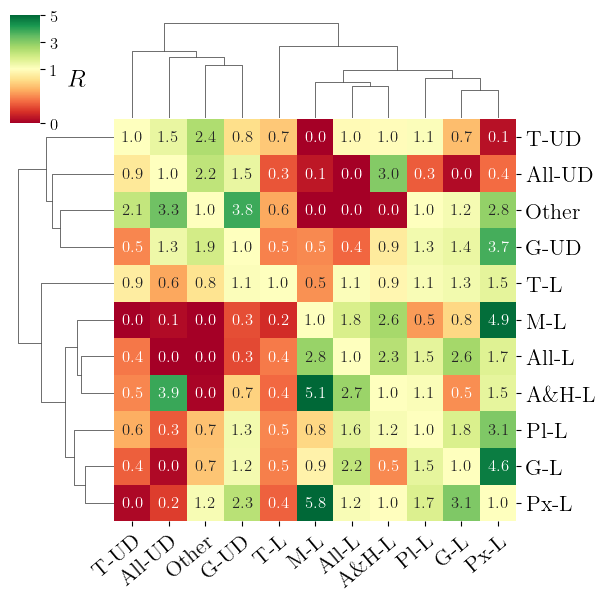

In [26]:
plot_heatmap(r_probit, probit_cov, name="probit-diversion-ratios")

./figures/gumbel-diversion-ratios


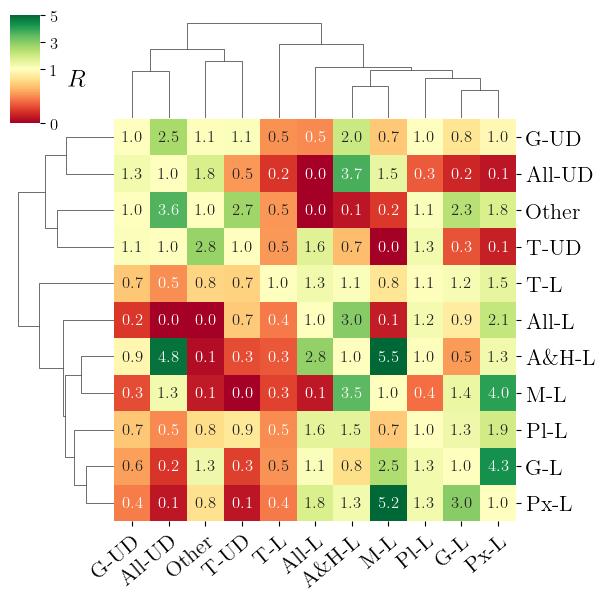

In [27]:
plot_heatmap(r_gumbel, gumbel_cov, name="gumbel-diversion-ratios")